# Estimate $k_F$ and $k_M$

## 1. Set up the notebook

Do imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *

## 2. Define constants

Define the acceleration of gravity in $\text{m} \;/\; \text{s}^2$:

In [2]:
g = 9.81

Define the mass of the drone in $\text{kg}$:

In [3]:
m = 0.04 # <-- FIXME

Define the principle moment of inertia about the $z$ axis in $\text{kg}\cdot\text{m}^2$:

In [4]:
J_z = 5.92e-05 # <-- FIXME

Using a ruler, measure the distance $\ell$ in **meters** along both the $x_B$ and $y_B$ axis from the center of mass to the center of each rotor. The position of the front-right rotor, for example, would then be expressed in the coordinates of the body-frame as

$$p^B_1 = \begin{bmatrix} \ell \\ -\ell \\ 0 \end{bmatrix}.$$

In [5]:
l = 0.03 # <-- FIXME

## 3. Find the force parameter

### 3.1 Describe the flight

The drone was commanded to first begin hovering 0.5 meters from the ground before moving to a position 0.5 + x above the ground, then to a position 0.5 - x above the ground, before returning to 0.5 meters and repeating the process 10 times with different x values.

``````
    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.55, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.45, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.56, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.44, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.57, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.43, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.54, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.46, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.57, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.43, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.6, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.4, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.59, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.41, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.58, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.42, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.57, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.43, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    # Move up to 0.53 meters:
    drone_client.move(0.0, 0.0, 0.61, 0.0, 2.0)
    # Move down to 0.47 meters:
    drone_client.move(0.0, 0.0, 0.39, 0.0, 2.0)
    # Return to hover at 0.50 meters:
    drone_client.move(0.0, 0.0, 0.50, 0.0, 2.0)

    drone_client.move(0.0, 0.0, 0.10, 0.0, 2.0)
``````


### 3.2 Get and plot flight data

Load and resample data.

In [6]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('force_data.json')

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=3.5,    # <-- FIXME
    t_max_offset=0.,    # <-- FIXME
)

Parse data to get:
* time
* the accelerometer measurements (**note!** these are in units of "$g$'s")
* the motor power commands

In [7]:
t = data_drone['time']
a_x = g * data_drone['acc.x']
a_y = g * data_drone['acc.y']
a_z = g * data_drone['acc.z']
m_1 = data_drone['motor.m1']
m_2 = data_drone['motor.m2']
m_3 = data_drone['motor.m3']
m_4 = data_drone['motor.m4']

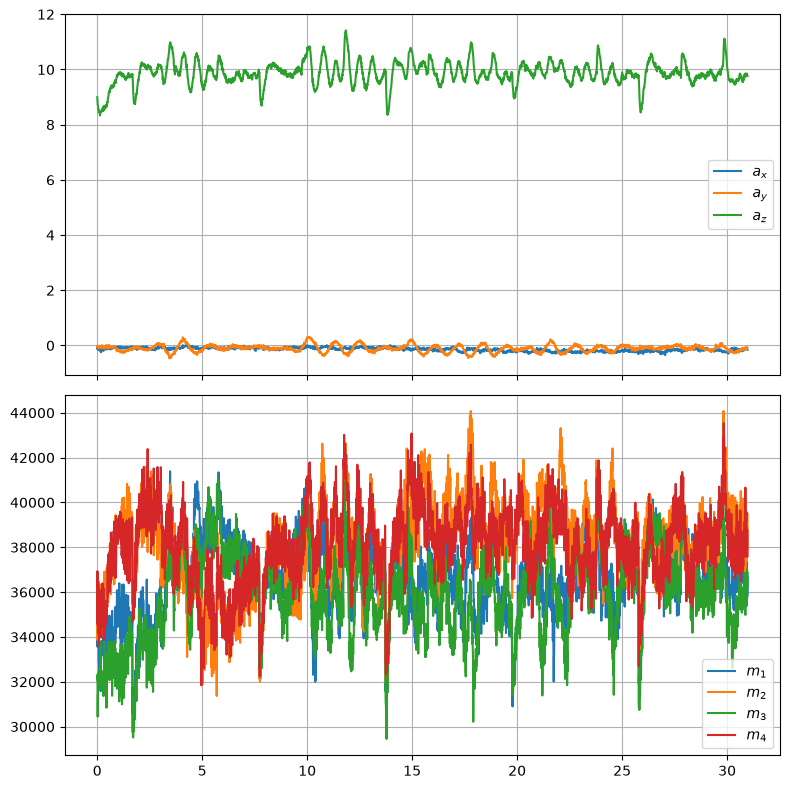

In [8]:
fig, (ax_a, ax_m) = plt.subplots(2, 1, figsize=(8, 8), sharex=True, tight_layout=True)
ax_a.plot(t, a_x, label=r'$a_x$')
ax_a.plot(t, a_y, label=r'$a_y$')
ax_a.plot(t, a_z, label=r'$a_z$')
ax_a.legend()
ax_a.grid()
ax_m.plot(t, m_1, label=r'$m_1$')
ax_m.plot(t, m_2, label=r'$m_2$')
ax_m.plot(t, m_3, label=r'$m_3$')
ax_m.plot(t, m_4, label=r'$m_4$')
ax_m.legend()
ax_m.grid()

### 3.3 Apply linear regression to estimate $k_F$ and $T_F$

In [9]:
def estimate_force_parameter(T_F):
    # Compute x(t)
    x = m_1 + m_2 + m_3 + m_4 # <-- FIXME
    
    # Compute y(t)
    y = m * a_z # <-- FIXME

    # Compute y(t + T_F)
    y = np.interp(t + T_F, t, y)

    # Compute estimate
    k_F = np.sum(x * y) / np.sum(x**2) # <-- FIXME

    # Compute RMSE
    RMSE = np.sqrt(np.mean((y - k_F * x)**2))

    return k_F, RMSE, x, y

Find the RMSE for a range of $T_F$.

In [10]:
# Create an array with a range of T_F's
T_Fs = np.linspace(0., 0.2, 401)

# Create an array to hold the RMSE for each T_F
RMSEs = np.empty_like(T_Fs)

# Find the RMSE for each T_F
for i, T_F in enumerate(T_Fs):
    k_F, RMSEs[i], x, y = estimate_force_parameter(T_F)

Find the value of $T_F$ that gives the minimum RMSE.

In [11]:
# Find the index of the minimum RMSE
i = np.argmin(RMSEs)           # <-- FIXME

# Find the minimum RMSE
RMSE = RMSEs[i]       # <-- FIXME

# Find the time shift that gives the minimum RMSE
T_F = T_Fs[i]    # <-- FIXME

Plot the RMSE for a range of $T_F$, showing the minimum.

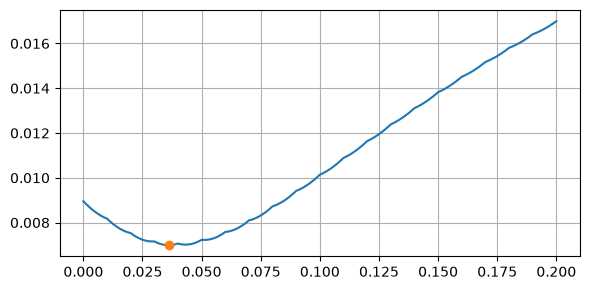

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), tight_layout=True)
ax.plot(T_Fs, RMSEs)
ax.plot(T_F, RMSE, '.', markersize=12)
ax.grid()

Recompute the estimate of $k_F$ for the value of $T_F$ that results in minimum RMSE.

In [13]:
k_F, RMSE, x, y = estimate_force_parameter(T_F)

Show the estimate.

In [14]:
print(f'k_F = {k_F:.2e}')
print(f'T_F = {T_F:.3f}')

k_F = 2.66e-06
T_F = 0.036


### 3.4 Validate your estimate

Show a plot that compares the predicted value of $f_z$ (i.e., $k_F x(t)$) with the measured value of $f_Z$ (i.e., $y(t + T_F)$), both as functions of $t$.

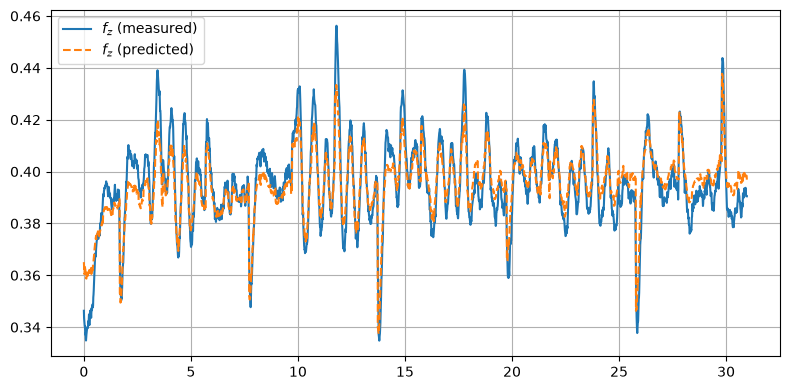

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t, y, label=r'$f_z$ (measured)')
ax.plot(t, k_F * x, '--', label=r'$f_z$ (predicted)')
ax.legend()
ax.grid()

Show a plot that compares the linear fit (i.e., $k_F x(t)$) to the raw data (i.e., $y(t + T_F)$), both as functions of $x(t)$.

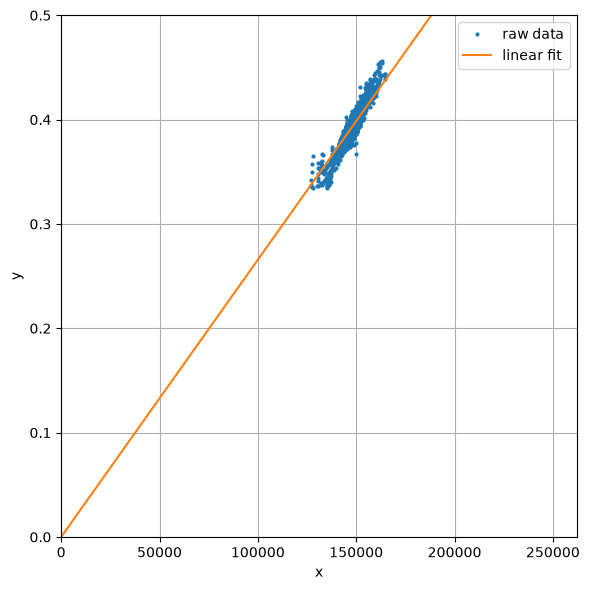

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), tight_layout=True)
ax.plot(x, y, '.', markersize=4, label='raw data')
ax.plot([0, 262140], [k_F * 0, k_F * 262140], label='linear fit')
ax.set_xlim(0, 262140)
ax.set_xlabel('x')
ax.set_ylim(0, 0.5)
ax.set_ylabel('y')
ax.legend()
ax.grid()

## 4. Find the moment parameter

### 4.1 Describe the flight

**Modify the text in this cell** to give a precise description of the flight trajectory, both in words and with the relevant code from `flight.py` (i.e., the sequence of stop and move commands). Please include code in markdown with a "code block" that is delimited by three backslashes above and below — for example, this...

``````
```python
drone_client.move(0.0, 0.0, 0.5, 0.0, 1.0)
```
``````
...is rendered like this:
```python
drone_client.move(0.0, 0.0, 0.5, 0.0, 1.0)
```

### 4.2 Get and plot flight data

Load and resample data.

In [17]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('moment_data.json')

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=4.,    # <-- FIXME
    t_max_offset=0.75,    # <-- FIXME
)

Parse data to get:
* time
* the gyroscope measurements (**note!** these are in units of degrees / second)
* the motor power commands

In [18]:
t = data_drone['time']
w_x = np.deg2rad(data_drone['gyro.x'])
w_y = np.deg2rad(data_drone['gyro.y'])
w_z = np.deg2rad(data_drone['gyro.z'])
m_1 = data_drone['motor.m1']
m_2 = data_drone['motor.m2']
m_3 = data_drone['motor.m3']
m_4 = data_drone['motor.m4']

Find the time step. It should be `0.01` because data were sampled at 100 Hz. (If it is not, stop and fix the problem.)

In [19]:
dt = t[1] - t[0]
print(f'dt = {dt}')

dt = 0.01


Plot gyroscope measurements and motor power commands, and check two things:
* Check that the $x$ and $y$ gyroscope measurements are much smaller than the $z$ gyroscope measurements. We would expect this to be true, because the drone was near hover during flight (only yawing back and forth). If this is not true, then something is wrong — fix the problem before going any further.
* Check that you are only seeing data from when the drone was *actually flying*. If this is not true, go back and adjust `t_min_offset` and `t_max_offset`.

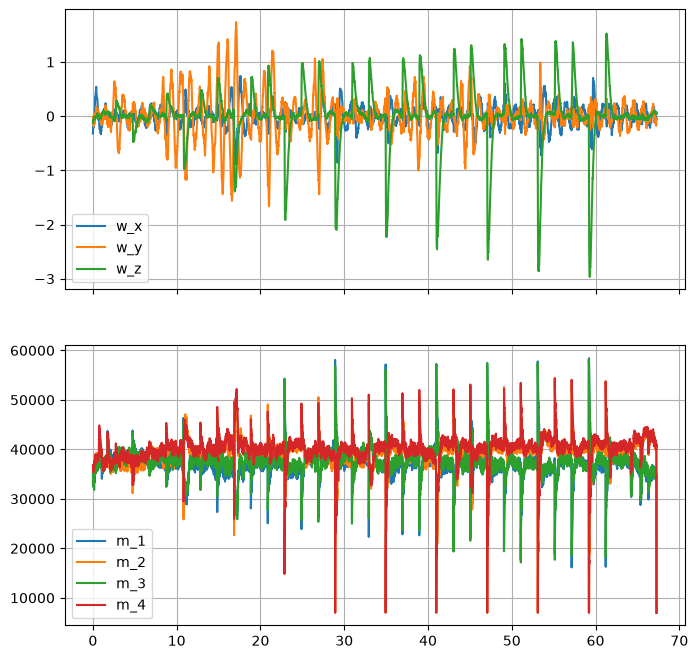

In [20]:
fig, (ax_w, ax_m) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
ax_w.plot(t, w_x, label='w_x')
ax_w.plot(t, w_y, label='w_y')
ax_w.plot(t, w_z, label='w_z')
ax_w.legend()
ax_w.grid()
ax_m.plot(t, m_1, label='m_1')
ax_m.plot(t, m_2, label='m_2')
ax_m.plot(t, m_3, label='m_3')
ax_m.plot(t, m_4, label='m_4')
ax_m.legend()
ax_m.grid()

### 4.3 Use finite difference to estimate $\dot{w}_z$

Estimate $\dot{w}_z$ by finite difference.

In [21]:
w_z_dot = (w_z[1:] - w_z[:-1]) / dt # <-- FIXME (REPLACE WITH CODE TO COMPUTE W_Z_DOT BY FINITE DIFFERENCE)

Truncate all other data so that everything has the same length.

In [22]:
# FIXME (REPLACE WITH CODE TO MODIFY t, m_1, etc.)
t = t[:-1]
m_1 = m_1[:-1]
m_2 = m_2[:-1]
m_3 = m_3[:-1]
m_4 = m_4[:-1]
w_z = w_z[:-1]



Plot both $w_z$ and $\dot{w}_z$ as a check to make sure finite difference was implemented correctly. (What should the sign of $\dot{w}_z$ be when $w_z$ is increasing, for example?)

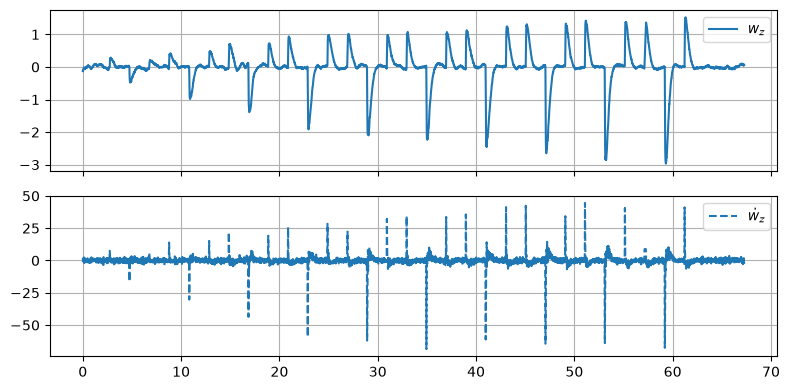

In [23]:
fig, (ax_w_z, ax_w_z_dot) = plt.subplots(2, 1, figsize=(8, 4), sharex=True, tight_layout=True)
ax_w_z.plot(t, w_z, label=r'$w_z$')
ax_w_z.legend()
ax_w_z.grid()
ax_w_z_dot.plot(t, w_z_dot, '--', label=r'$\dot{w}_z$')
ax_w_z_dot.legend()
ax_w_z_dot.grid()

### 4.4 Apply linear regression to estimate $k_M$ and $T_M$

Write a function to estimate $k_M$ for a given $T_M$.

In [24]:
def estimate_kM(T_M):
    # Compute x(t)
    x = -m_1 + m_2 - m_3 + m_4 # <-- FIXME
    
    # Compute y(t)
    y = J_z * w_z_dot # <-- FIXME

    # Compute y(t + T_M)
    y = np.interp(t + T_M, t, y)

    # Compute estimate
    k_M = np.sum(x * y) / np.sum(x**2) # <-- FIXME

    # Compute RMSE
    RMSE = np.sqrt(np.mean((y - k_M * x)**2))

    return k_M, RMSE, x, y

Find the RMSE for a range of $T_M$.

In [25]:
# Create an array with a range of T's
T_Ms = np.linspace(0., 0.2, 401)

# Create an array to hold the RMSE for each T
RMSEs = np.empty_like(T_Ms)

# Find the RMSE for each T_M
for i, T_M in enumerate(T_Ms):
    k_M, RMSEs[i], x, y = estimate_kM(T_M)

Find the value of $T_M$ that gives the minimum RMSE.

In [26]:
# Find the index of the minimum RMSE
i = np.argmin(RMSEs)           # <-- FIXME

# Find the minimum RMSE
RMSE = RMSEs[i]       # <-- FIXME

# Find the time shift that gives the minimum RMSE
T_M = T_Ms[i]        # <-- FIXME

Plot the RMSE for a range of $T_M$, showing the minimum.

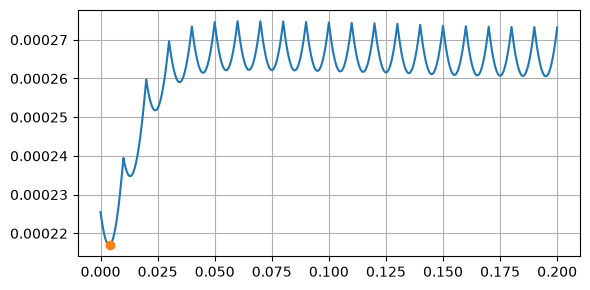

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), tight_layout=True)
ax.plot(T_Ms, RMSEs)
ax.plot(T_M, RMSE, '.', markersize=12)
ax.grid()

Recompute the estimate of $k_F$ for the value of $T_M$ that results in minimum RMSE.

In [28]:
k_M, RMSE, x, y = estimate_kM(T_M)

Show the estimate.

In [29]:
print(f'k_M = {k_M:.2e}')
print(f'T_M = {T_M:.3f}')

k_M = 1.16e-08
T_M = 0.004


### 4.5 Validate your estimate

Show a plot that compares the predicted value of $\tau_z$ (i.e., $k_M x(t)$) with the measured value of $\tau_Z$ (i.e., $y(t + T_M)$), both as functions of $t$.

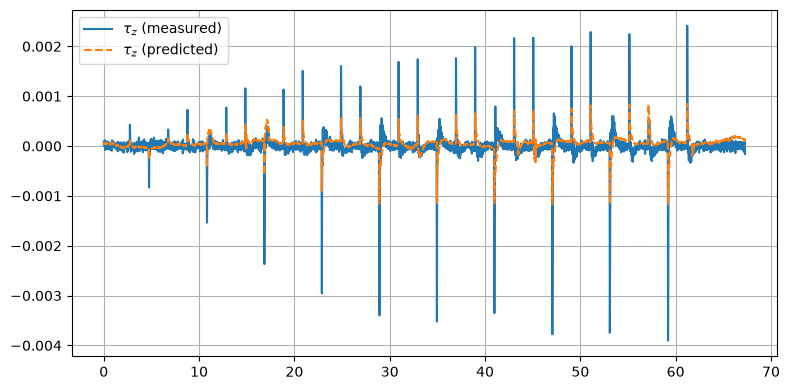

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t, y, label=r'$\tau_z$ (measured)')
ax.plot(t, k_M * x, '--', label=r'$\tau_z$ (predicted)')
ax.legend()
ax.grid()

Show a plot that compares the linear fit (i.e., $k_M x$ versus $x$) to the raw data (i.e., $y(t + T_M)$ versus $x(t)$).

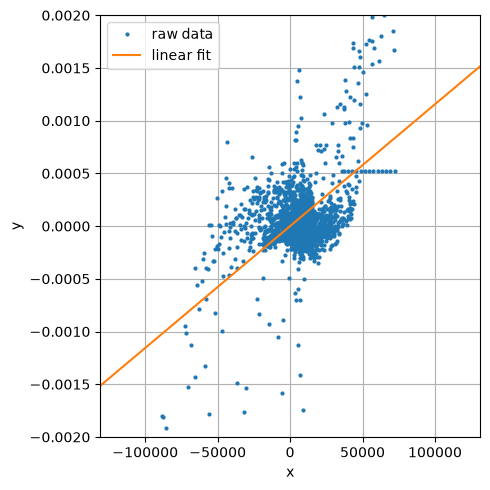

In [31]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5), tight_layout=True)
ax.plot(x, y, '.', markersize=4, label='raw data')
ax.plot([-131070, 131070], [k_M * -131070, k_M * 131070], label='linear fit')
ax.set_xlim(-131070, 131070)
ax.set_xlabel('x')
ax.set_ylim(-.002, 0.002)
ax.set_ylabel('y')
ax.legend()
ax.grid()

## 5. Summarize and discuss the results

### 5.1 Summary of results

In [32]:
print(f'l = {l:.3f} m')
print(f'k_F = {k_F:.2e} N  (T_F = {T_F:.3f} s)')
print(f'k_M = {k_M:.2e} N  (T_M = {T_M:.3f} s)')

l = 0.030 m
k_F = 2.66e-06 N  (T_F = 0.036 s)
k_M = 1.16e-08 N  (T_M = 0.004 s)


### 5.2 Conclusions about time delay

**Modify the text in this cell** to answer the following questions about your results:

* What is the delay between the time at which a motor command is given and the time at which the corresponding rotor produces a force along the $z_B$ axis? Do you consider this delay to be significant?

The time delay at which a motor command gets acctuated to produce a force along the $z_B$ axis is around 36 one-thousandths of a second. In a more precise application, this may be the difference between success and failure. But for the current useages of the drone this delay is not too significant. 

* What is the delay between the time at which a motor command is given and the time at which the corresponding rotor produces a moment about the $z_B$ axis? Do you consider this delay to be significant?

The time delay at which a motor command gets acctuated to produce a moment about the $z_B$ axis is on 4 one-thousands of a second. As such this delay is far less significant in pure magnitude.

Then, based on your answers to these first two questions, answer four more:

* What delay would you expect between the time at which your controller asks for a net torque $\tau_x$ and the time at which that torque is produced? Do you consider this delay to be significant?

* What delay would you expect between the time at which your controller asks for a net torque $\tau_y$ and the time at which that torque is produced? Do you consider this delay to be significant?

The expected delays to produce a net torque about the $x_B$ and $y_B$ axes are similar to the delay inherent in the $f_z$ acctuation as the torque is produced by a variance in the $z_B$ force produced by each rotor. At around 36 one-thousands of a second this seems to be a fair reaction time for most applications in this lab.


* What delay would you expect between the time at which your controller asks for a net torque $\tau_z$ and the time at which that torque is produced? Do you consider this delay to be significant?

The expected delay to produce a net torque about the $z_B$ axis is as stated above, 4 one-thousandths of a second and is well within a reasonable reaction time for most yaw manuevers. 

* What delay would you expect between the time at which your controller asks for a net force $f_z$ and the time at which that force is produced? Do you consider this delay to be significant?

The expected delay to produce a net force in the $z_B$ direction is as stated above, 36 one-thousandths of a second. This is not significant when used in slow approach manuevers but may become an issue in more rapid manuevers and recovery attempts.

Please justify your answers (don't just say "yes" or "no").

### 5.3 Sources of error

**Modify the text in this cell** to discuss possible sources of error. For example:

* How uncertain was each measurement and each computed quantity?
The mass carries over an uncertainty of 0.001 grams, the span incurred an uncertainty of 0.5 mm, and the J_z carries over an uncertainty of 1.07e-05.


* What assumptions were made and to what extent were these assumptions violated?

Two such assumptions for this lab was that the rotors are identical with the same force and moment coefficients and that there is a linear proportionality between the motor command and the force and torque produced. 

You may find that these questions are harder to answer than in the previous lab.

### 5.4 Ways to improve the results

Similar to the issue stated below on running multiple flights to obtain resolvable data, the increase in flight data would help to remove the variance caused by naturally unsteady flight that the drone was observed to go through in many of the flights including the final one used for data. 

### 5.5 Reflection

Review the reflection you put in your Lab 3 notebook. **Modify the text in this cell** to answer the following three questions with at least one sentence each:
* What was your biggest struggle this week? Was it the same or different from last week?

The biggest struggle occured with the necesity to repeat flights to obtain sufficiently varied data. Similar to last weeks, the confirmation of good data was the most difficult part of the procedure.


* What was the most important thing you learned this week?

The most important thing learned was the estimation procedure of estimating the relation between commands and effects on the drone and the time delay of these commands.

* How does what you learned this week relate to what you learned last week?

This lab utilized the estimated mass and moment of inertria found in the last lab.